---
# 0. Librerías y configuración global

Se fija la **semilla aleatoria** (`SEED = 42`) para que todos los resultados sean reproducibles. Los archivos CSV deben estar en la misma carpeta que este cuaderno (o se modifica `DATA_DIR`).

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             balanced_accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.utils.class_weight import compute_sample_weight
from scipy.stats import loguniform, randint

warnings.filterwarnings('ignore')

SEED     = 42            # semilla global (reproducibilidad)
DATA_DIR = '.'           # carpeta donde están los CSV
FIG_DIR  = 'figuras'     # carpeta de salida de las figuras
os.makedirs(FIG_DIR, exist_ok=True)
np.random.seed(SEED)

import sklearn
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

scikit-learn 1.9.1 | pandas 3.1.1 | numpy 2.4.6


### Estilo gráfico académico y código de diferenciación

Para que los tres modelos se distingan **incluso en una impresión en blanco y negro**, cada uno tiene un color, un tipo de línea, un marcador y un patrón de relleno propios:

| Modelo | Color | Línea | Marcador | Relleno de barras |
|---|---|---|---|---|
| Regresión logística | azul | continua | círculo | liso |
| Random Forest | verde | discontinua | cuadrado | rayas `//` |
| Gradient Boosting | rojo | punto-raya | triángulo | cruces `xx` |

In [2]:
plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['DejaVu Serif', 'Times New Roman'],
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.30, 'grid.linestyle': '--',
    'legend.frameon': False, 'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
})

ORDEN = ['Regresión logística', 'Random Forest', 'Gradient Boosting']
COL   = {'Regresión logística': '#1f4e9c', 'Random Forest': '#2a8c4a', 'Gradient Boosting': '#c0392b'}
LS    = {'Regresión logística': '-',       'Random Forest': '--',      'Gradient Boosting': '-.'}
MK    = {'Regresión logística': 'o',       'Random Forest': 's',       'Gradient Boosting': '^'}
HATCH = {'Regresión logística': '',        'Random Forest': '//',      'Gradient Boosting': 'xx'}
CMAP  = {'Regresión logística': 'Blues',   'Random Forest': 'Greens',  'Gradient Boosting': 'Reds'}
DS_NOMBRE = {'A': 'Tabla A (bank_full_modelo)'}

def guardar(fig, nombre):
    fig.savefig(f'{FIG_DIR}/{nombre}.png')
    plt.show()

---
# 1. c.1 — Preparación final de los datos

## 1.1 Carga de la tabla minable

In [3]:
from pathlib import Path

TABLA_DIR = Path("tabla_minable")

modelo = pd.read_csv(TABLA_DIR / "bank_full_modelo.csv")
print(f'Tabla A (bank_full_modelo)    : {modelo.shape[0]:,} filas x {modelo.shape[1]} columnas')

display(modelo.head(3))

Tabla A (bank_full_modelo)    : 45,208 filas x 43 columnas


,age,day,balance_log,campaign_cap,previous_cap,default_bin,housing_bin,loan_bin,balance_negativo,job_imputada,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown,yb
0,58,5,7.670429,1,0,0,1,0,0,0,...,0,0,1,0,0,0,0,0,1,0
1,44,5,3.401197,1,0,0,1,0,0,0,...,0,0,1,0,0,0,0,0,1,0
2,33,5,1.098612,1,0,0,1,1,0,0,...,0,0,1,0,0,0,0,0,1,0


## 1.2 Verificación de calidad y consistencia entre las tablas

Antes de modelar se comprueba que (i) la variable objetivo `yb` existe y es binaria (0/1), (ii) todas las columnas predictoras son numéricas y (iii) no hay valores faltantes que impidan entrenar.

In [4]:
# (i)-(ii) Verificación de la variable objetivo y del tipo de las columnas en la Tabla A
assert 'yb' in modelo.columns, "Falta la columna objetivo 'yb'"
assert set(modelo['yb'].unique()) <= {0, 1}, "'yb' debe ser binaria (0/1)"
assert all(np.issubdtype(t, np.number) for t in modelo.dtypes), 'Hay columnas no numéricas en la Tabla A'
print('OK: tabla verificada correctamente.\n')

# (iii) Calidad de la Tabla A
calidad = pd.DataFrame({
    'Filas':               [len(modelo)],
    'Columnas':            [modelo.shape[1]],
    'Valores nulos':       [int(modelo.isna().sum().sum())],
    'Columnas con nulos':  [int((modelo.isna().sum() > 0).sum())],
    'Filas duplicadas':    [int(modelo.duplicated().sum())],
}, index=['Tabla A'])
display(calidad)

print('Columnas con nulos en la Tabla A:')
display(modelo.isna().sum()[modelo.isna().sum() > 0].to_frame('nulos'))

OK: tabla verificada correctamente.



,Filas,Columnas,Valores nulos,Columnas con nulos,Filas duplicadas
Tabla A,45208,43,0,0,20


Columnas con nulos en la Tabla A:


,nulos


## 1.3 Análisis exploratorio mínimo de la variable objetivo

El desbalance de clases condiciona **toda** la estrategia de modelado (métricas, pesos de clase, umbral de decisión), por eso se cuantifica primero.

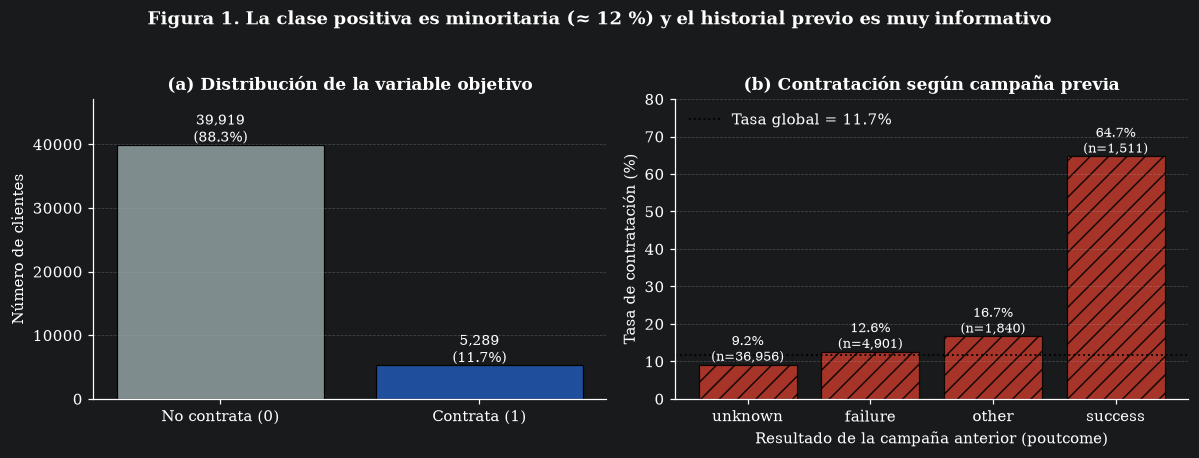

Razón de desbalance (negativos : positivos) = 7.55 : 1


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# (a) Distribución de la variable objetivo
cuentas = modelo['yb'].value_counts().reindex([0, 1])
barras = ax[0].bar(['No contrata (0)', 'Contrata (1)'], cuentas.values, color=['#7f8c8d', '#1f4e9c'],
                   edgecolor='black', linewidth=0.8)
for b, v in zip(barras, cuentas.values):
    ax[0].text(b.get_x() + b.get_width()/2, v + 500, f'{v:,}\n({v/len(modelo):.1%})', ha='center', fontsize=9)
ax[0].set_ylabel('Número de clientes'); ax[0].set_ylim(0, cuentas.max()*1.18)
ax[0].set_title('(a) Distribución de la variable objetivo')
ax[0].grid(axis='x', visible=False)

# (b) Tasa de contratación según el resultado de la campaña anterior (poutcome)
# bank_full_modelo codifica poutcome con dummies; 'failure' es la categoría de referencia (sin columna)
orden_p = ['unknown', 'failure', 'other', 'success']
grupo_p = np.select([modelo['poutcome_success'] == 1, modelo['poutcome_other'] == 1, modelo['poutcome_unknown'] == 1],
                    ['success', 'other', 'unknown'], default='failure')
tasa_p = modelo.groupby(grupo_p)['yb'].agg(['mean', 'count']).reindex(orden_p)
b2 = ax[1].bar(orden_p, tasa_p['mean']*100, color='#c0392b', edgecolor='black', linewidth=0.8, hatch='//', alpha=0.85)
for b, (m_, n_) in zip(b2, tasa_p.itertuples(index=False)):
    ax[1].text(b.get_x() + b.get_width()/2, m_*100 + 1, f'{m_:.1%}\n(n={n_:,})', ha='center', fontsize=8.5)
ax[1].axhline(modelo['yb'].mean()*100, color='black', ls=':', lw=1.2, label=f"Tasa global = {modelo['yb'].mean():.1%}")
ax[1].set_ylabel('Tasa de contratación (%)'); ax[1].set_ylim(0, 80)
ax[1].set_xlabel('Resultado de la campaña anterior (poutcome)')
ax[1].set_title('(b) Contratación según campaña previa'); ax[1].legend(loc='upper left')
ax[1].grid(axis='x', visible=False)

fig.suptitle('Figura 1. La clase positiva es minoritaria (≈ 12 %) y el historial previo es muy informativo', y=1.03, fontweight='bold')
fig.tight_layout(); guardar(fig, 'fig01_distribucion_objetivo')
print(f"Razón de desbalance (negativos : positivos) = {cuentas.loc[0]/cuentas.loc[1]:.2f} : 1")

## 1.4 Construcción de la matriz de características final

### Tabla A — `bank_full_modelo.csv`
Ya está lista para modelar: todas las columnas son numéricas y no hay nulos. Se separa la variable objetivo `yb` (**y**) del resto (**X**). Las seis variables continuas se estandarizarán únicamente dentro del pipeline de la regresión logística; las dummies (0/1) se dejan sin tocar.

In [6]:
y = modelo['yb'].astype(int)

# ---------- Tabla A ----------
X_A = modelo.drop(columns='yb').copy()
cont_A = ['age', 'day', 'balance_log', 'campaign_cap', 'previous_cap', 'dias_desde_contacto_previo']
bin_A  = [c for c in X_A.columns if c not in cont_A]
cat_A  = []

print(f'Tabla A -> X: {X_A.shape} | continuas: {len(cont_A)} | binarias (dummies): {len(bin_A)}')
assert X_A.isna().sum().sum() == 0 and all(np.issubdtype(t, np.number) for t in X_A.dtypes)

Tabla A -> X: (45208, 42) | continuas: 6 | binarias (dummies): 36


## 1.5 División en conjuntos de entrenamiento y prueba

Se separa el **80 % para entrenar** y el **20 % para probar**. Decisiones y justificación:

| Parámetro de `train_test_split` | Valor | Justificación |
|---|---|---|
| `test_size` | `0.20` | Regla estándar 80/20: 36 166 clientes para aprender y 9 042 para una evaluación estable (≈ 1 058 positivos en prueba). |
| `stratify` | `y` | **Estratificación**: conserva la proporción de clases (≈ 11,7 % de positivos) en ambos conjuntos. Imprescindible con clases desbalanceadas. |
| `random_state` | `42` | Reproducibilidad. |
| `shuffle` | `True` (por defecto) | Rompe el orden cronológico del archivo. |

> **Detalle importante:** la partición se hace **una sola vez sobre los índices** y se aplica a la Tabla A. Así, los tres algoritmos se entrenan y se evalúan sobre **exactamente los mismos clientes**, y la comparación entre modelos es justa.

El conjunto de prueba **no se toca** hasta la evaluación final: el ajuste de hiperparámetros y del umbral se hace solo con validación cruzada sobre el conjunto de entrenamiento.

,Clientes,Positivos,% positivos
Total,45208,5289,11.7
Entrenamiento (80 %),36166,4231,11.7
Prueba (20 %),9042,1058,11.7


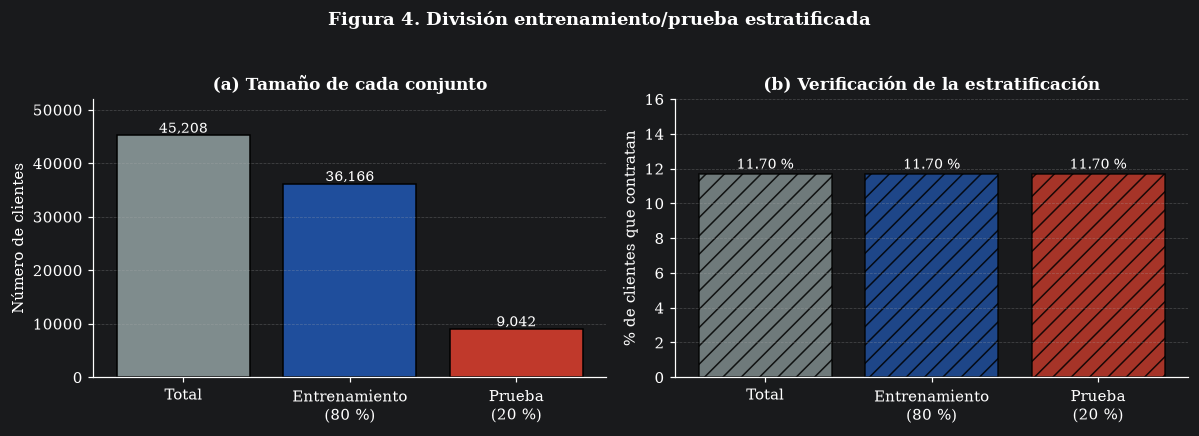

Los tres modelos se entrenan con 36166 clientes y se evalúan con 9042 clientes de prueba.


In [7]:
idx = np.arange(len(y))
idx_tr, idx_te = train_test_split(idx, test_size=0.20, stratify=y, random_state=SEED)

DATOS = {
    'A': dict(X_tr=X_A.iloc[idx_tr], X_te=X_A.iloc[idx_te]),
}
for k in DATOS:
    DATOS[k]['y_tr'] = y.iloc[idx_tr]
    DATOS[k]['y_te'] = y.iloc[idx_te]

y_tr, y_te = DATOS['A']['y_tr'], DATOS['A']['y_te']
resumen_split = pd.DataFrame({
    'Clientes':   [len(y), len(y_tr), len(y_te)],
    'Positivos':  [int(y.sum()), int(y_tr.sum()), int(y_te.sum())],
    '% positivos': [y.mean()*100, y_tr.mean()*100, y_te.mean()*100],
}, index=['Total', 'Entrenamiento (80 %)', 'Prueba (20 %)'])
display(resumen_split.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
nombres = ['Total', 'Entrenamiento\n(80 %)', 'Prueba\n(20 %)']
bs = ax[0].bar(nombres, resumen_split['Clientes'], color=['#7f8c8d', '#1f4e9c', '#c0392b'], edgecolor='black')
for b_, v in zip(bs, resumen_split['Clientes']):
    ax[0].text(b_.get_x()+b_.get_width()/2, v+500, f'{v:,}', ha='center', fontsize=9)
ax[0].set_ylabel('Número de clientes'); ax[0].set_title('(a) Tamaño de cada conjunto'); ax[0].set_ylim(0, 52000)
ax[0].grid(axis='x', visible=False)

bs = ax[1].bar(nombres, resumen_split['% positivos'], color=['#7f8c8d', '#1f4e9c', '#c0392b'], edgecolor='black', hatch='//', alpha=0.85)
for b_, v in zip(bs, resumen_split['% positivos']):
    ax[1].text(b_.get_x()+b_.get_width()/2, v+0.3, f'{v:.2f} %', ha='center', fontsize=9)
ax[1].set_ylabel('% de clientes que contratan'); ax[1].set_ylim(0, 16)
ax[1].set_title('(b) Verificación de la estratificación'); ax[1].grid(axis='x', visible=False)
fig.suptitle('Figura 4. División entrenamiento/prueba estratificada', y=1.03, fontweight='bold')
fig.tight_layout(); guardar(fig, 'fig04_division_train_test')

assert len(DATOS['A']['X_tr']) == len(y_tr) and len(DATOS['A']['X_te']) == len(y_te)
assert set(idx_tr).isdisjoint(idx_te)      # ningún cliente está a la vez en entrenamiento y prueba
print('Los tres modelos se entrenan con', len(y_tr), 'clientes y se evalúan con', len(y_te), 'clientes de prueba.')

---
# 2. c.2 — Selección de los algoritmos

**Tipo de problema → algoritmo.** Como la variable objetivo es binaria (contrata / no contrata), se trata de **clasificación supervisada**. Se proponen **tres modelos** de familias distintas y, además, cada uno se entrena en **dos versiones** (línea base y versión con hiperparámetros optimizados), de modo que la comparación incluye el efecto del ajuste de parámetros.

| Modelo | Familia | Por qué se elige |
|---|---|---|
| **Regresión logística** | Lineal, paramétrico | Línea base interpretable (coeficientes → *odds ratios*). |
| **Random Forest** | Ensamble por *bagging* de árboles | Captura no linealidades e interacciones; robusto al ruido; poca sensibilidad a la escala. |
| **Gradient Boosting** | Ensamble por *boosting* de árboles | Suele dar el mejor desempeño en datos tabulares; corrige secuencialmente los errores del modelo previo. |

## 2.1 Regresión logística

Modela la probabilidad de contratar como una función sigmoide de una combinación lineal de las variables:

$$P(y=1\mid \mathbf{x}) = \sigma(z)=\frac{1}{1+e^{-z}},\qquad z=\beta_0+\sum_{j=1}^{p}\beta_j x_j$$

Los coeficientes se estiman minimizando la **pérdida logarítmica con regularización L2**:

$$\min_{\boldsymbol\beta}\ \ \tfrac12\lVert\boldsymbol\beta\rVert_2^2 \;+\; C\sum_{i=1}^{n} w_i\,\log\!\big(1+e^{-\tilde y_i z_i}\big)$$

| Parámetro | Valor usado | Explicación |
|---|---|---|
| `C` | línea base `1.0`; búsqueda `loguniform(1e-3, 1e2)` | **Inverso de la fuerza de regularización**. `C` pequeño → coeficientes más encogidos (modelo más simple, menos sobreajuste); `C` grande → ajuste más libre. Se explora en escala logarítmica porque su efecto es multiplicativo. |
| `penalty` / regularización | L2 (por defecto) | Penaliza la suma de cuadrados de los coeficientes; estabiliza la estimación con variables correlacionadas (p. ej. las dummies de mes). |
| `solver` | `lbfgs` (por defecto) | Optimizador cuasi-Newton, adecuado para L2 y datos de tamaño medio. |
| `max_iter` | `2000` | Máximo de iteraciones; se sube desde 100 para garantizar convergencia. |
| `class_weight` | `'balanced'` | Pesa cada clase con $w_c = n/(2\,n_c)$: cada positivo recibe ≈ 4,27 y cada negativo ≈ 0,57, es decir, un positivo pesa ≈ 7,5 veces más que un negativo. Evita que el modelo ignore la clase minoritaria. |
| `random_state` | `42` | Reproducibilidad. |
| *Preprocesamiento* | `StandardScaler` en las variables continuas | La regularización y el optimizador son sensibles a la escala; sin estandarizar, `C` penalizaría de forma desigual a cada variable. |

## 2.2 Random Forest

Entrena $B$ árboles de decisión sobre **muestras bootstrap** de los datos y, en cada división, solo considera un **subconjunto aleatorio de variables**. Al promediar árboles poco correlacionados se reduce la varianza sin aumentar mucho el sesgo:

$$\hat P(y=1\mid\mathbf x)=\frac1B\sum_{b=1}^{B} T_b(\mathbf x)$$

Cada árbol elige sus cortes minimizando la **impureza de Gini**, $G=1-\sum_k p_k^2$.

| Parámetro | Valor línea base → espacio de búsqueda | Explicación |
|---|---|---|
| `n_estimators` | `200` → entero en [150, 400] | Número de árboles $B$. Más árboles reducen la varianza, con rendimientos decrecientes. |
| `max_depth` | `10` → {6, 8, 10, 12, 16, None} | Profundidad máxima. Controla la complejidad: árboles muy profundos memorizan el ruido. |
| `min_samples_leaf` | `5` → {1, 3, 5, 10, 20} | Mínimo de observaciones por hoja. Valores altos suavizan las predicciones (regularización). |
| `max_features` | `'sqrt'` → {'sqrt', 0.3, 0.5} | Variables evaluadas en cada corte. Menos variables → árboles más diversos y menos correlacionados. |
| `class_weight` | `'balanced_subsample'` → {'balanced', 'balanced_subsample'} | Reponderación de clases (la segunda recalcula los pesos en cada muestra bootstrap). |
| `bootstrap` | `True` (por defecto) | Muestreo con reemplazo de las filas de cada árbol. |
| `criterion` | `'gini'` (por defecto) | Medida de impureza. |
| `random_state` | `42` | Reproducibilidad. |

## 2.3 Gradient Boosting

Construye un modelo **aditivo y secuencial**: cada árbol pequeño $h_m$ se ajusta al **gradiente negativo de la pérdida** (en clasificación con `log_loss`, los residuos $r_i=y_i-\hat p_i$) del modelo acumulado, y se suma con un factor de aprendizaje $\nu$:

$$F_m(\mathbf x)=F_{m-1}(\mathbf x)+\nu\, h_m(\mathbf x),\qquad \hat P(y=1\mid\mathbf x)=\sigma\big(F_M(\mathbf x)\big)$$

| Parámetro | Valor línea base → espacio de búsqueda | Explicación |
|---|---|---|
| `n_estimators` | `300` → {200, 300, 400} | Número **máximo** de árboles $M$. Con parada temprana (ver abajo) el número real suele ser menor. |
| `learning_rate` ($\nu$) | `0.1` → `loguniform(0.02, 0.2)` | Contribución de cada árbol. Valores pequeños = aprendizaje más lento pero más preciso (requieren más árboles). Es el parámetro más influyente junto con `n_estimators`. |
| `max_depth` | `3` → {2, 3, 4, 5} | Profundidad de los árboles base. En *boosting* se usan árboles **débiles** (poco profundos) para evitar el sobreajuste. |
| `subsample` | `0.8` → {0.6, …, 1.0} | Fracción de filas usada por árbol (*Stochastic Gradient Boosting*). Valores < 1 reducen la varianza. |
| `min_samples_leaf` | `20` → {10, 20, 50, 100} | Mínimo de observaciones por hoja (regularización). |
| `max_features` | `None` → {None, 'sqrt', 0.5} | Variables consideradas en cada corte (aleatoriza y acelera). |
| `n_iter_no_change` | `10` | **Parada temprana**: se detiene si en 10 iteraciones consecutivas no mejora la pérdida en el conjunto de validación interno. |
| `validation_fraction` | `0.1` | 10 % de los datos de entrenamiento se reserva internamente para la parada temprana. |
| `loss` | `'log_loss'` (por defecto) | Pérdida logarítmica = verosimilitud binomial. |
| `sample_weight` | `'balanced'` | `GradientBoostingClassifier` no tiene `class_weight`; el equivalente es pasar pesos por muestra en `fit`. |
| `random_state` | `42` | Reproducibilidad. |

## 2.4 Diseño experimental

| Elemento | Decisión |
|---|---|
| Conjuntos | 80 % entrenamiento / 20 % prueba, estratificado (sección 1.5). |
| Tabla | A (`bank_full_modelo`): **3 modelos** en total (3 algoritmos), cada uno con su línea base y su versión optimizada. |
| Búsqueda de hiperparámetros | `RandomizedSearchCV` con **10 configuraciones aleatorias** por modelo (búsqueda aleatoria: más eficiente que una malla completa cuando hay varios hiperparámetros continuos). |
| Validación | Validación cruzada **estratificada de 3 particiones** (`StratifiedKFold`) **solo dentro del entrenamiento**. |
| Métrica de selección | **AUC-PR** (`average_precision`): es la más informativa con clases desbalanceadas porque se centra en la clase positiva. |
| Umbral de decisión | Se elige el umbral que maximiza **F1** sobre predicciones *out-of-fold* del entrenamiento (nunca sobre la prueba). |
| Evaluación final | Una sola vez sobre el 20 % de prueba. |

---
# 3. Entrenamiento de los modelos

## 3.1 Preprocesamiento por tabla y configuración de los modelos

El preprocesamiento va **dentro de un `Pipeline`** de scikit-learn. Esto evita la **fuga de información** del preprocesamiento: el escalador y el codificador se ajustan solo con los datos de cada partición de entrenamiento y nunca ven los datos de validación o de prueba.

In [8]:
# Grupos de columnas por tabla
GRUPOS = {
    'A': dict(cont=cont_A, bin=bin_A, cat=cat_A),
}

def crear_preprocesador(ds, escalar):
    # ColumnTransformer: estandariza las continuas (si escalar), deja pasar las binarias y codifica las categóricas.
    g = GRUPOS[ds]
    piezas = [('cont', StandardScaler() if escalar else 'passthrough', g['cont']),
              ('bin',  'passthrough', g['bin'])]
    if g['cat']:
        piezas.append(('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), g['cat']))
    return ColumnTransformer(piezas, verbose_feature_names_out=False)

# Configuración de los tres algoritmos: línea base y espacio de búsqueda
CONFIG = {
    'Regresión logística': dict(
        clasificador=lambda **kw: LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED, **kw),
        escalar=True, pesos=False,
        base=dict(C=1.0),
        espacio={'clf__C': loguniform(1e-3, 1e2)},
        n_iter=10),
    'Random Forest': dict(
        clasificador=lambda **kw: RandomForestClassifier(random_state=SEED, n_jobs=1, **kw),
        escalar=False, pesos=False,
        base=dict(n_estimators=200, max_depth=10, min_samples_leaf=5, max_features='sqrt',
                  class_weight='balanced_subsample'),
        espacio={'clf__n_estimators': randint(150, 401),
                 'clf__max_depth': [6, 8, 10, 12, 16, None],
                 'clf__min_samples_leaf': [1, 3, 5, 10, 20],
                 'clf__max_features': ['sqrt', 0.3, 0.5],
                 'clf__class_weight': ['balanced', 'balanced_subsample']},
        n_iter=10),
    'Gradient Boosting': dict(
        clasificador=lambda **kw: GradientBoostingClassifier(n_iter_no_change=10, validation_fraction=0.1,
                                                              tol=1e-4, random_state=SEED, **kw),
        escalar=False, pesos=True,
        base=dict(n_estimators=300, learning_rate=0.1, max_depth=3, subsample=0.8, min_samples_leaf=20),
        espacio={'clf__n_estimators': [200, 300, 400],
                 'clf__learning_rate': loguniform(0.02, 0.2),
                 'clf__max_depth': [2, 3, 4, 5],
                 'clf__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
                 'clf__min_samples_leaf': [10, 20, 50, 100],
                 'clf__max_features': [None, 'sqrt', 0.5]},
        n_iter=10),
}

CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
print('Configuración cargada para:', list(CONFIG))

Configuración cargada para: ['Regresión logística', 'Random Forest', 'Gradient Boosting']


## 3.2 Funciones de evaluación y de entrenamiento

`entrenar_modelo(tabla, algoritmo)` ejecuta, para un algoritmo y una tabla, los tres pasos del procedimiento:

1. **Línea base:** entrena con los parámetros de las tablas de la sección 2 y evalúa en prueba.
2. **Búsqueda aleatoria** de hiperparámetros con validación cruzada estratificada (métrica: AUC-PR) y reajuste con los mejores sobre todo el entrenamiento.
3. **Umbral óptimo** de F1 obtenido con predicciones *out-of-fold* del entrenamiento; con él se evalúa una única vez en el conjunto de prueba.

In [9]:
def metricas(y_real, proba, umbral):
    # Métricas independientes del umbral (AUC) y dependientes del umbral (resto)
    pred = (proba >= umbral).astype(int)
    return {'AUC_ROC': roc_auc_score(y_real, proba), 'AUC_PR': average_precision_score(y_real, proba),
            'Accuracy': accuracy_score(y_real, pred), 'Bal_Acc': balanced_accuracy_score(y_real, pred),
            'Precision': precision_score(y_real, pred, zero_division=0), 'Recall': recall_score(y_real, pred),
            'F1': f1_score(y_real, pred), 'MCC': matthews_corrcoef(y_real, pred), 'Umbral': umbral}

def umbral_f1(y_real, proba):
    # Umbral que maximiza F1 sobre las probabilidades dadas
    p, r, t = precision_recall_curve(y_real, proba)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[np.argmax(f1)])

RES = {'A': {}}      # almacén de resultados

def entrenar_modelo(ds, nombre):
    cfg, d = CONFIG[nombre], DATOS[ds]
    X_tr, y_tr_, X_te, y_te_ = d['X_tr'], d['y_tr'], d['X_te'], d['y_te']
    fp = {'clf__sample_weight': compute_sample_weight('balanced', y_tr_)} if cfg['pesos'] else {}
    t0 = time.time()

    # (1) Línea base
    pipe_base = Pipeline([('prep', crear_preprocesador(ds, cfg['escalar'])), ('clf', cfg['clasificador'](**cfg['base']))])
    pipe_base.fit(X_tr, y_tr_, **fp)
    p_base = pipe_base.predict_proba(X_te)[:, 1]

    # (2) Búsqueda aleatoria de hiperparámetros (validación cruzada solo sobre entrenamiento)
    pipe = Pipeline([('prep', crear_preprocesador(ds, cfg['escalar'])), ('clf', cfg['clasificador']())])
    busq = RandomizedSearchCV(pipe, cfg['espacio'], n_iter=cfg['n_iter'], scoring='average_precision', cv=CV,
                              n_jobs=-1, random_state=SEED, refit=True, return_train_score=True)
    busq.fit(X_tr, y_tr_, **fp)
    mejor = busq.best_estimator_

    # (3) Umbral óptimo con predicciones out-of-fold del entrenamiento
    oof = cross_val_predict(clone(mejor), X_tr, y_tr_, cv=CV, method='predict_proba', params=fp, n_jobs=-1)[:, 1]
    umbral = umbral_f1(y_tr_, oof)
    p_te = mejor.predict_proba(X_te)[:, 1]

    RES[ds][nombre] = dict(
        pipe=mejor, cv=pd.DataFrame(busq.cv_results_), mejores=busq.best_params_, cv_score=busq.best_score_,
        p_base=p_base, p_te=p_te, umbral=umbral,
        m_base=metricas(y_te_, p_base, 0.5), m_opt=metricas(y_te_, p_te, umbral), segundos=time.time() - t0)

    r = RES[ds][nombre]
    print(f'{nombre} | bank_full_modelo.csv  ({r["segundos"]:.0f} s)')
    print('  Mejores hiperparámetros :', {k.replace('clf__', ''): (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
                                           for k, v in r['mejores'].items()})
    if nombre == 'Gradient Boosting':
        print('  Árboles realmente usados (parada temprana):', r['pipe'].named_steps['clf'].n_estimators_)
    print(f'  AUC-PR  validación cruzada = {r["cv_score"]:.4f}')
    print(f'  Línea base  -> AUC-ROC {r["m_base"]["AUC_ROC"]:.4f} | AUC-PR {r["m_base"]["AUC_PR"]:.4f}')
    print(f'  Optimizado  -> AUC-ROC {r["m_opt"]["AUC_ROC"]:.4f} | AUC-PR {r["m_opt"]["AUC_PR"]:.4f} '
          f'| umbral {umbral:.3f} | Recall {r["m_opt"]["Recall"]:.3f} | Precision {r["m_opt"]["Precision"]:.3f} '
          f'| F1 {r["m_opt"]["F1"]:.3f}')

## 3.3 Entrenamiento sobre `bank_full_modelo.csv`

### Modelo 1 — Regresión logística

In [10]:
entrenar_modelo('A', 'Regresión logística')

Regresión logística | bank_full_modelo.csv  (10 s)
  Mejores hiperparámetros : {'C': 0.0746}
  AUC-PR  validación cruzada = 0.4016
  Línea base  -> AUC-ROC 0.7771 | AUC-PR 0.4200
  Optimizado  -> AUC-ROC 0.7778 | AUC-PR 0.4205 | umbral 0.637 | Recall 0.448 | Precision 0.453 | F1 0.451


### Modelo 2 — Random Forest

In [11]:
entrenar_modelo('A', 'Random Forest')

Random Forest | bank_full_modelo.csv  (114 s)
  Mejores hiperparámetros : {'class_weight': 'balanced', 'max_depth': 16, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 360}
  AUC-PR  validación cruzada = 0.4349
  Línea base  -> AUC-ROC 0.7965 | AUC-PR 0.4364
  Optimizado  -> AUC-ROC 0.8031 | AUC-PR 0.4550 | umbral 0.557 | Recall 0.526 | Precision 0.458 | F1 0.490


### Modelo 3 — Gradient Boosting

In [12]:
entrenar_modelo('A', 'Gradient Boosting')

Gradient Boosting | bank_full_modelo.csv  (60 s)
  Mejores hiperparámetros : {'learning_rate': 0.0482, 'max_depth': 5, 'max_features': None, 'min_samples_leaf': 50, 'n_estimators': 200, 'subsample': 0.8}
  Árboles realmente usados (parada temprana): 128
  AUC-PR  validación cruzada = 0.4411
  Línea base  -> AUC-ROC 0.8039 | AUC-PR 0.4515
  Optimizado  -> AUC-ROC 0.8059 | AUC-PR 0.4603 | umbral 0.611 | Recall 0.531 | Precision 0.454 | F1 0.489
